# Tugas Praktikum - SVM Suara dan Histogram Siang/Malam

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/tugas-praktikum)

## Tugas 1 - SVM suara dengan enam kombinasi split/kernel

Menggunakan seluruh 20 fitur numerik `voice.csv`, membuang duplikat identik, lalu melakukan split stratified 70:30 dan 80:20 (seed 42). StandardScaler hanya di-fit pada train. Ketiga kernel memakai C=1; polynomial degree=3 dan gamma=scale; RBF gamma=scale. Parameter tetap untuk perbandingan yang konsisten.

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python
Ukuran setelah deduplikasi: (3166, 21)


,Split,Kernel,Train N,Test N,Akurasi train,Akurasi test,Macro F1 test
0,70:30,linear,2216,950,0.9761,0.9737,0.9737
1,70:30,poly,2216,950,0.9662,0.9579,0.9579
2,70:30,rbf,2216,950,0.9856,0.9811,0.9811
3,80:20,linear,2532,634,0.9759,0.9732,0.9732
4,80:20,poly,2532,634,0.9668,0.9621,0.9621
5,80:20,rbf,2532,634,0.9850,0.9826,0.9826


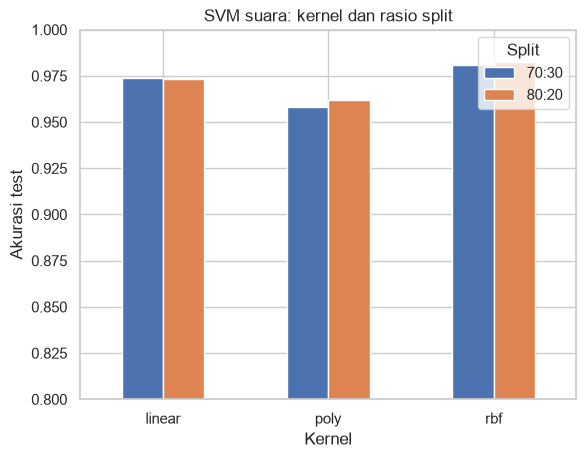

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
np.random.seed(42)
sns.set_theme(style='whitegrid')
print('Kernel:', sys.executable)

from sklearn.svm import SVC
from sklearn.metrics import f1_score
data = pd.read_csv('data/voice.csv').drop_duplicates().reset_index(drop=True)
X, y = data.drop(columns='label'), data['label']
print('Ukuran setelah deduplikasi:', data.shape)
voice_rows, voice_predictions = [], {}
for test_size, split in [(0.3, '70:30'), (0.2, '80:20')]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=42)
    assert set(X_train.index).isdisjoint(X_test.index)
    for kernel in ['linear', 'poly', 'rbf']:
        model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1, degree=3, gamma='scale'))
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        voice_rows.append({'Split': split, 'Kernel': kernel, 'Train N': len(y_train), 'Test N': len(y_test),
                           'Akurasi train': model.score(X_train, y_train),
                           'Akurasi test': accuracy_score(y_test, pred),
                           'Macro F1 test': f1_score(y_test, pred, average='macro')})
        voice_predictions[(split, kernel)] = (y_test, pred)
voice_comparison = pd.DataFrame(voice_rows)
display(voice_comparison.round(4))
voice_comparison.pivot(index='Kernel', columns='Split', values='Akurasi test').plot.bar(
    ylim=(0.8, 1), ylabel='Akurasi test', title='SVM suara: kernel dan rasio split', rot=0)
plt.show()

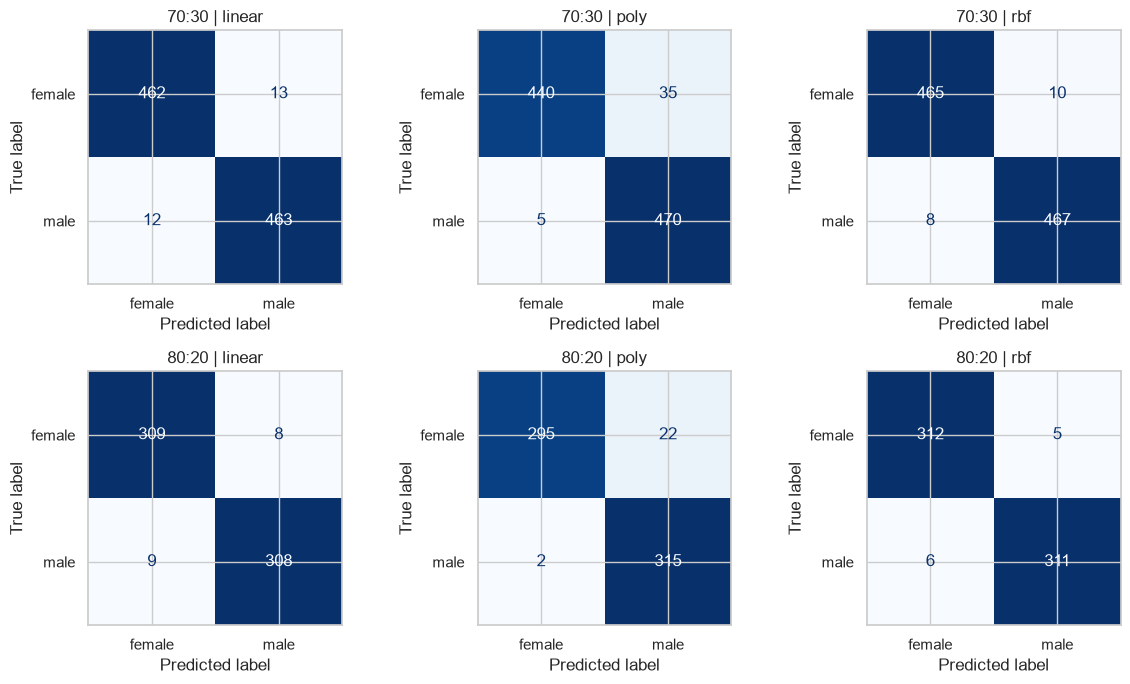

Tabel memenuhi keenam kombinasi yang diminta. Perbedaan antar rasio juga dipengaruhi oleh anggota test yang berbeda; gunakan perbandingan kernel dalam rasio yang sama. Hasil ini membandingkan konfigurasi tetap dan tidak memilih parameter memakai test.

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, ((split, kernel), (actual, predicted)) in zip(axes.flat, voice_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(actual, predicted, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{split} | {kernel}')
plt.tight_layout()
plt.show()
display(Markdown('Tabel memenuhi keenam kombinasi yang diminta. Perbedaan antar rasio juga dipengaruhi '
                 'oleh anggota test yang berbeda; gunakan perbandingan kernel dalam rasio yang sama. '
                 'Hasil ini membandingkan konfigurasi tetap dan tidak memilih parameter memakai test.'))

## Tugas 2 - Histogram HSV, split 80:20, dan tuning RBF

Seluruh 400 citra dari Praktikum 5 digabung lalu dibagi ulang 80:20 sesuai tugas. Fitur: histogram kanal H/S/V, masing-masing 32 bin, dinormalisasi per kanal (96 fitur). Gambar memakai resize yang sama dengan praktikum. Tuning C dan gamma menggunakan 5-fold CV hanya pada training. Hash piksel diperiksa agar citra identik tidak bocor antar split.

Gambar awal: 400 | Gambar unik: 399


Fitur: (399, 96) | Train: 319 | Test: 80


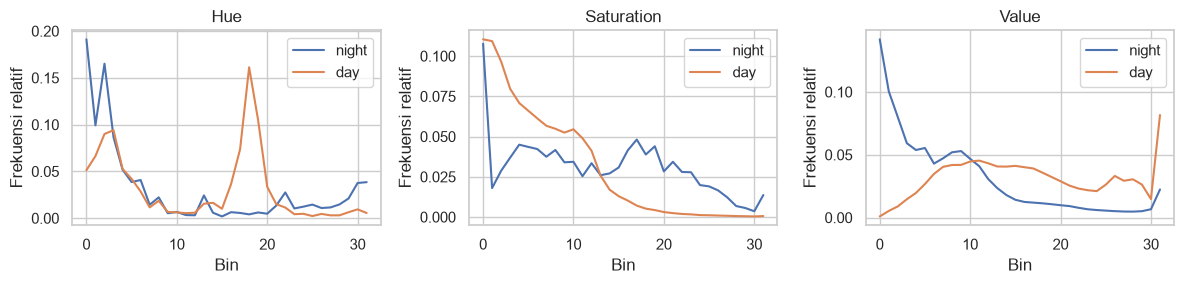

In [3]:
import cv2
from zipfile import ZipFile
from PIL import Image
def load_dataset(split):
    # Baca JPG langsung dari arsip asli tanpa mengekstrak metadata macOS.
    loaded = []
    with ZipFile('data/images.zip') as archive:
        for filename in sorted(archive.namelist()):
            p = Path(filename)
            if filename.startswith(f'images/{split}/') and p.suffix.lower() == '.jpg':
                label = p.parent.name
                if label not in {'day', 'night'}:
                    continue
                with archive.open(filename) as file:
                    loaded.append((np.asarray(Image.open(file).convert('RGB')), label, filename))
    assert loaded, f'Tidak ada gambar pada split {split}'
    return loaded

def standarized_input(image):
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    return {'night': 0, 'day': 1}[label]

def avg_brightness(image):
    return float(cv2.cvtColor(image, cv2.COLOR_RGB2HSV)[:, :, 2].mean())

def random_img_viz(img_list):
    index = np.random.default_rng(42).integers(len(img_list))
    image, label, _ = img_list[index]
    plt.imshow(image)
    plt.title(f'Label: {label} | shape: {image.shape}')
    plt.axis('off')
    plt.show()

def extract_avg_bright_feature(img_list):
    # Resize satu gambar pada satu waktu agar tidak menyimpan ratusan citra besar.
    return pd.DataFrame([{'AVG_BRIGHT': avg_brightness(standarized_input(image)),
                          'LABELS': label_encoder(label), 'file': filename}
                         for image, label, filename in img_list])

import hashlib
images = load_dataset('training') + load_dataset('test')
def histogram_hsv(image, bins=32):
    hsv = cv2.cvtColor(standarized_input(image), cv2.COLOR_RGB2HSV)
    features = []
    for channel, upper in [(0, 180), (1, 256), (2, 256)]:
        hist = cv2.calcHist([hsv], [channel], None, [bins], [0, upper]).ravel()
        features.append(hist / hist.sum())
    return np.concatenate(features)
seen, clean_images = set(), []
for image, label, filename in images:
    digest = hashlib.sha256(image.tobytes()).hexdigest()
    if digest not in seen:
        seen.add(digest)
        clean_images.append((image, label, filename))
print('Gambar awal:', len(images), '| Gambar unik:', len(clean_images))
X = np.array([histogram_hsv(image) for image, _, _ in clean_images])
y = np.array([label_encoder(label) for _, label, _ in clean_images])
all_ids = np.arange(len(y))
train_ids, test_ids = train_test_split(all_ids, test_size=0.2, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = X[train_ids], X[test_ids], y[train_ids], y[test_ids]
assert set(train_ids).isdisjoint(test_ids) and X.shape[1] == 96
print('Fitur:', X.shape, '| Train:', len(y_train), '| Test:', len(y_test))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, start, name in zip(axes, [0, 32, 64], ['Hue', 'Saturation', 'Value']):
    for label, label_name in [(0, 'night'), (1, 'day')]:
        # Visualisasi fitur memakai data training saja.
        ax.plot(X_train[y_train == label, start:start+32].mean(axis=0), label=label_name)
    ax.set(title=name, xlabel='Bin', ylabel='Frekuensi relatif')
    ax.legend()
plt.tight_layout()
plt.show()

## Training dan pencarian hyperparameter

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
grid = GridSearchCV(pipeline, {'svc__C': [0.1, 1, 10, 100],
                              'svc__gamma': ['scale', 0.001, 0.01, 0.1]},
                    scoring='accuracy', cv=cv, n_jobs=2)
grid.fit(X_train, y_train)
print('Parameter terbaik:', grid.best_params_)
print('Akurasi CV:', grid.best_score_)
display(pd.DataFrame(grid.cv_results_)[['param_svc__C', 'param_svc__gamma', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).head(10))

Parameter terbaik: {'svc__C': 1, 'svc__gamma': 'scale'}
Akurasi CV: 0.9905257936507936


,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
4,1.0,scale,0.990526,0.012674
6,1.0,0.01,0.990526,0.012674
8,10.0,scale,0.990526,0.012674
9,10.0,0.001,0.990526,0.012674
10,10.0,0.01,0.990526,0.012674
12,100.0,scale,0.990526,0.012674
13,100.0,0.001,0.990526,0.012674
14,100.0,0.01,0.990526,0.012674
5,1.0,0.001,0.987450,0.006276
0,0.1,scale,0.968651,0.000198


## Evaluasi test dan analisis

,Model,Akurasi train,Akurasi test
0,Histogram RBF default,1.0,0.975
1,Histogram RBF pilihan CV,1.0,0.975


              precision    recall  f1-score   support

       night       0.95      1.00      0.98        40
         day       1.00      0.95      0.97        40

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



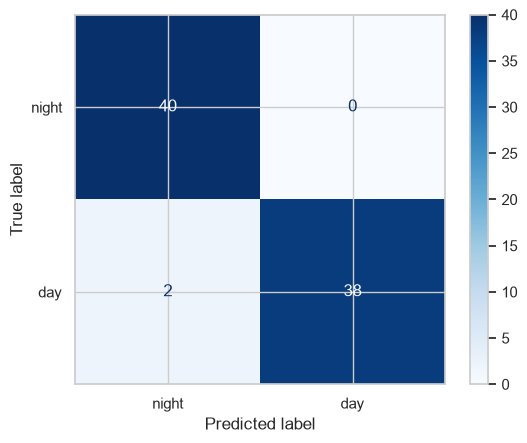

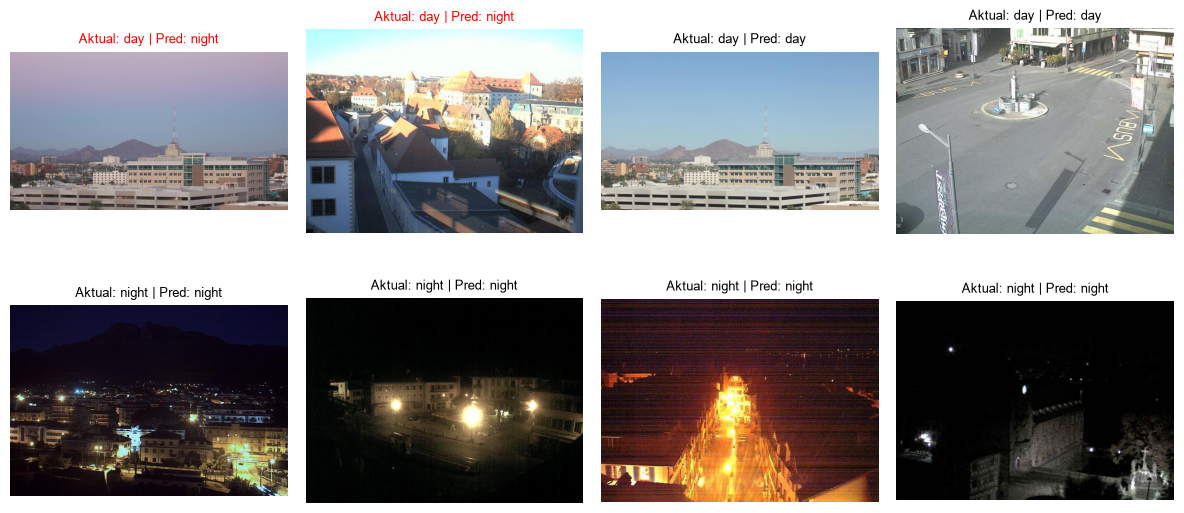

**Akurasi test histogram HSV + SVM RBF: 0.9750**; akurasi CV **0.9905**, dengan parameter **{'svc__C': 1, 'svc__gamma': 'scale'}**. Histogram menyimpan distribusi warna/kecerahan lebih lengkap daripada satu nilai rata-rata. Skor ini tidak dibandingkan langsung dengan test bawaan Praktikum 5 karena anggota split berbeda. Dataset hanya 400 citra sehingga kesalahan beberapa gambar dapat mengubah skor secara terlihat.

In [5]:
best = grid.best_estimator_
pred = best.predict(X_test)
baseline = make_pipeline(StandardScaler(), SVC(kernel='rbf')).fit(X_train, y_train)
display(pd.DataFrame([
    {'Model': 'Histogram RBF default', 'Akurasi train': baseline.score(X_train, y_train),
     'Akurasi test': baseline.score(X_test, y_test)},
    {'Model': 'Histogram RBF pilihan CV', 'Akurasi train': best.score(X_train, y_train),
     'Akurasi test': accuracy_score(y_test, pred)}
]).round(4))
print(classification_report(y_test, pred, target_names=['night', 'day'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['night', 'day'], cmap='Blues')
plt.show()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
wrong = np.flatnonzero(pred != y_test)
examples = np.concatenate([wrong, np.flatnonzero(pred == y_test)])[:8]
for ax, j in zip(axes.flat, examples):
    image, actual_label, _ = clean_images[test_ids[j]]
    ax.imshow(image)
    ax.set_title(f'Aktual: {actual_label} | Pred: {"day" if pred[j] else "night"}',
                 color='black' if pred[j] == y_test[j] else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()
display(Markdown(f'**Akurasi test histogram HSV + SVM RBF: {accuracy_score(y_test, pred):.4f}**; '
                 f'akurasi CV **{grid.best_score_:.4f}**, dengan parameter **{grid.best_params_}**. '
                 'Histogram menyimpan distribusi warna/kecerahan lebih lengkap daripada satu nilai rata-rata. '
                 'Skor ini tidak dibandingkan langsung dengan test bawaan Praktikum 5 karena anggota split berbeda. '
                 'Dataset hanya 400 citra sehingga kesalahan beberapa gambar dapat mengubah skor secara terlihat.'))